# MLC Comparisons

In [ ]:
"""
File Name: mlc_comparisons.ipynb

Author:
    Francesco De Zan
    delta phi remote sensing GmbH

Date: August 2025

Description:
------------
This script performs a comparison of different phase products in terms of mean and standard deviation. 

Usage:
------
To use this script, define the following parameters:
    
    - cslc_file_name
    - cmlc_file_name
    - cmlc_ndc_file_name
    - cmlc_direct_file_name
    - cmlc_emi_file_name


"""

In [1]:
#Input CLSC product path 
base_dir = "/media/data/SAR/L2/Naples/DSC/S4/"
channel_dir = "SAOCOM_DSC_S4_20250220_POLARIZATION_VV/"
cslc_file_name = base_dir + channel_dir

In [ ]:
# CMLC product file paths
cmlc_file_name = base_dir +  "cmlcs_memory_param_0.95_drift_control_1.0_ma_0.0_mini_size_10_norm.zarr"
cmlc_ndc_file_name = base_dir +"cmlcs_no_drift_control_0.4.zarr"
cmlc_direct_file_name = base_dir +"cmlcs_direct.zarr"
cmlc_emi_file_name = base_dir +"cmlcs_emi.zarr"

In [3]:
import numpy as np
import datatree
import xarray as xr
import matplotlib.pyplot as plt
from tqdm import tqdm
import shutil

In [4]:
import rosel.io
import rosel.computation
import rosel.shiroma

In [ ]:
type, n_jobs, job_memory = ["LOCAL", 14, None]
client = rosel.computation.create_client(type, n_jobs, job_memory)

In [6]:
# loading cmlc products
ds_cmlc = datatree.open_datatree(cmlc_file_name, engine='zarr', chunks={})
ds_cmlc_no_drift_control = datatree.open_datatree(cmlc_ndc_file_name, engine='zarr', chunks={})
ds_cmlc_direct = datatree.open_datatree(cmlc_direct_file_name, engine='zarr', chunks={})
ds_emi = datatree.open_datatree(cmlc_emi_file_name, engine='zarr', chunks={})

In [ ]:
# multilooking parameters retrieved from ds_cmlc
multilook = ds_cmlc.attrs['multilook']
w_rg = multilook['slant_range_time']
w_az = multilook['azimuth_time']

In [ ]:
# opening the CSLC dataset
ds = datatree.open_datatree(cslc_file_name, engine='zarr', chunks={})

cstack = ds.coreg.cstack
N = len(cstack)

In [9]:
dates = [np.datetime64(str(cstack[n].acquisition_date.data)) for n in range(0,N)]

In [10]:
# initialization for full-scene version
n_lines, n_samples = cstack[0].shape
n_rg = np.floor_divide(n_samples, w_rg)
n_az = np.floor_divide(n_lines, w_az)

In [11]:
def make_interf_(A, B):
    return (A.conj() * B).coarsen(azimuth_time=w_az, slant_range_time=w_rg, boundary='trim').mean()

def make_coh_(A, B):
    return make_interf_(A,B) / (np.sqrt(make_interf_(A,A) * make_interf_(B,B))).fillna(1)

In [13]:
# Selecting two acquisitions for visualization
n1 = 65
n2 = 66

print(cstack[n1].acquisition_date.values)
print(cstack[n2].acquisition_date.values)

2025-01-14T17:05:41.969028
2025-01-30T17:05:44.272096


In [14]:
phase_cmlc = xr.apply_ufunc(np.angle, ds_cmlc.phase[n2,:,:] * np.conj(ds_cmlc.phase[n1,:,:]), dask='parallelized')
phase_cmlc_ndc = xr.apply_ufunc(np.angle, ds_cmlc_no_drift_control.phase[n2,:,:] * np.conj(ds_cmlc_no_drift_control.phase[n1,:,:]), dask='parallelized')
phase_cmlc_direct = xr.apply_ufunc(np.angle, ds_cmlc_direct.phase[n2,:,:] * np.conj(ds_cmlc_direct.phase[n1,:,:]), dask='parallelized')
phase_emi = xr.apply_ufunc(np.angle, ds_emi.phase[n2,:,:] * np.conj(ds_emi.phase[n1,:,:]), dask='parallelized')

In [ ]:
phase_direct = xr.apply_ufunc(np.angle, make_interf_(cstack[n1], cstack[n2]), dask='parallelized').compute()
coh_direct = xr.apply_ufunc(np.abs, make_coh_(cstack[n1], cstack[n2]), dask='parallelized').compute()

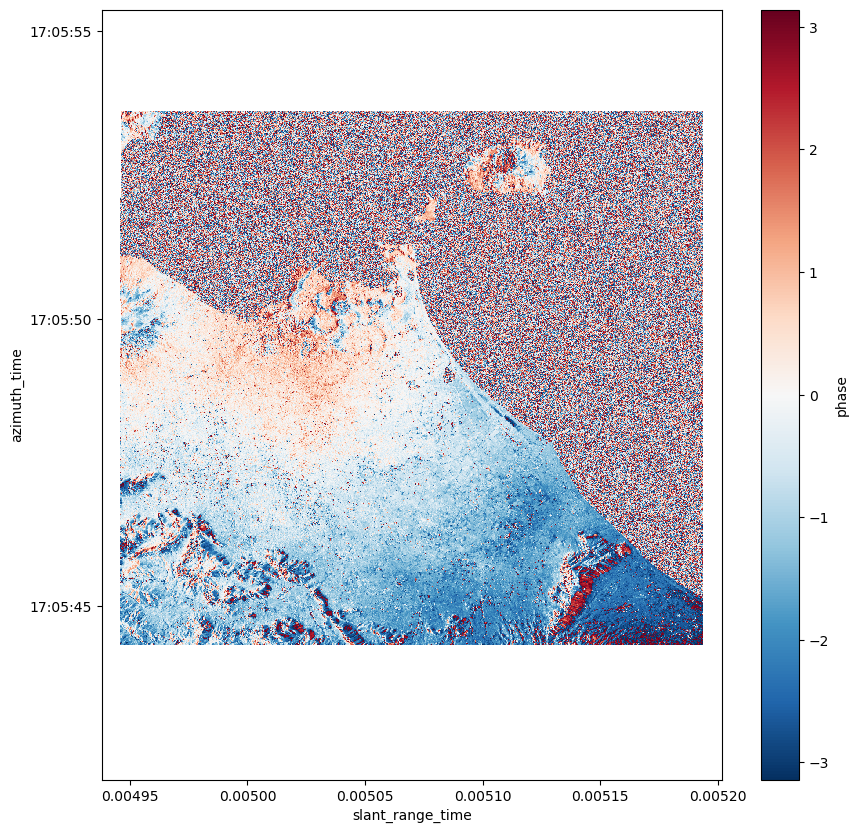

In [16]:
plt.figure(figsize=(10,10))
phase_cmlc.plot()

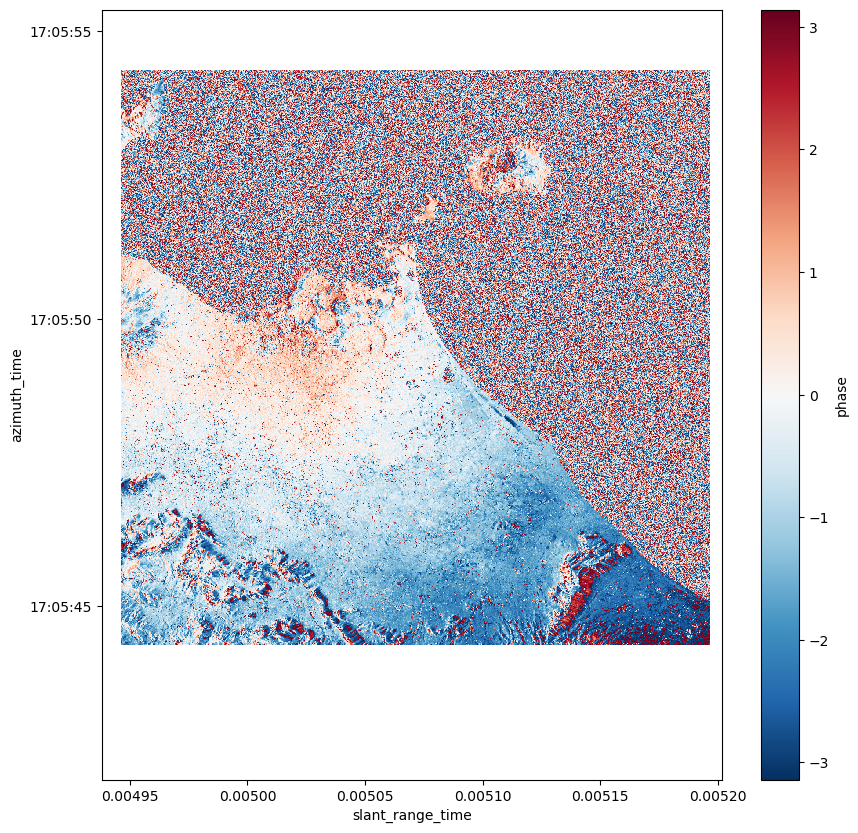

In [17]:
plt.figure(figsize=(10,10))
phase_emi.plot()

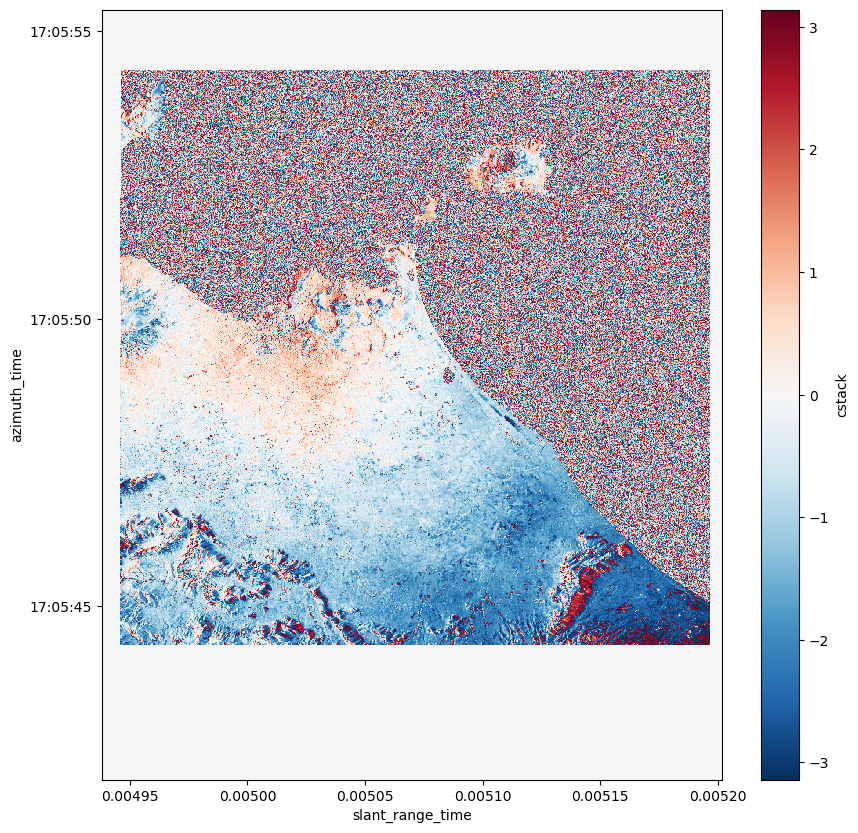

In [18]:
plt.figure(figsize=(10,10))
phase_direct.plot()

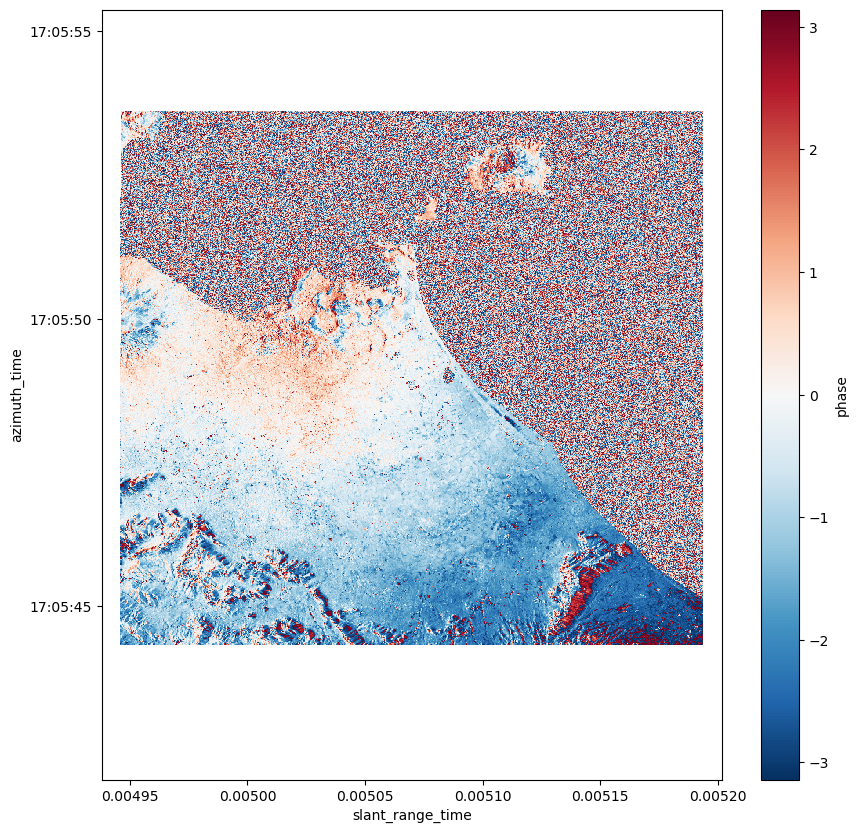

In [19]:
plt.figure(figsize=(10,10))
phase_cmlc_ndc.plot()

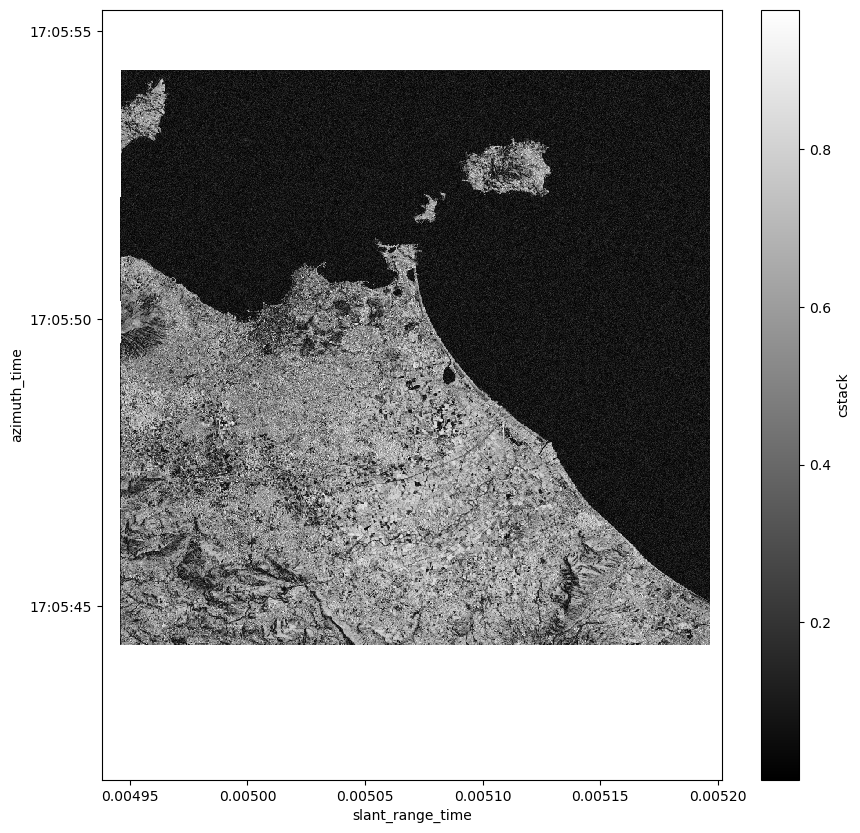

In [20]:
plt.figure(figsize=(10,10))
coh_direct.plot(cmap='gray')

In [ ]:
cmlc_bias = np.zeros(N)
ndc_bias = np.zeros(N)
emi_bias = np.zeros(N)
cmlc_emi_bias = np.zeros(N)
cmlc_emi_bias_s1 = np.zeros(N)
ndc_emi_bias = np.zeros(N)
ndc_emi_bias_s1 = np.zeros(N)

cmlc_std = np.zeros(N)
ndc_std = np.zeros(N)
emi_std = np.zeros(N)
cmlc_emi_std = np.zeros(N)


n1 = 0

mask_cmlc = ds_cmlc.short_term_coherence[30] > 0.2

for n2 in tqdm(range(0,N,1)):
    # load phases
    phase_cmlc = xr.apply_ufunc(np.angle, ds_cmlc.phase[n2,:,:] * np.conj(ds_cmlc.phase[n1,:,:]), dask='parallelized')
    phase_cmlc_ndc = xr.apply_ufunc(np.angle, ds_cmlc_no_drift_control.phase[n2,:,:] * np.conj(ds_cmlc_no_drift_control.phase[n1,:,:]), dask='parallelized')
    phase_cmlc_direct = xr.apply_ufunc(np.angle, ds_cmlc_direct.phase[n2,:,:] * np.conj(ds_cmlc_direct.phase[n1,:,:]), dask='parallelized')
    phase_emi = xr.apply_ufunc(np.angle, ds_emi.phase[n2,:,:] * np.conj(ds_emi.phase[n1,:,:]), dask='parallelized')
    
    # compute differences
    phase_diff_cmlc_direct = np.exp(1j*(phase_cmlc - phase_cmlc_direct))
    phase_diff_cmlc_direct = xr.apply_ufunc(np.angle, phase_diff_cmlc_direct, dask='parallelized')
    phase_diff_ndc_direct = np.exp(1j*(phase_cmlc_ndc - phase_cmlc_direct))
    phase_diff_ndc_direct = xr.apply_ufunc(np.angle, phase_diff_ndc_direct, dask='parallelized')
    phase_diff_emi_direct = np.exp(1j*(phase_emi - phase_cmlc_direct))
    phase_diff_emi_direct = xr.apply_ufunc(np.angle, phase_diff_emi_direct, dask='parallelized')
    phase_diff_cmlc_emi = np.exp(1j*(phase_cmlc - phase_emi))
    phase_diff_cmlc_emi = xr.apply_ufunc(np.angle, phase_diff_cmlc_emi, dask='parallelized')
    phase_diff_ndc_emi = np.exp(1j*(phase_cmlc_ndc - phase_emi))
    phase_diff_ndc_emi = xr.apply_ufunc(np.angle, phase_diff_ndc_emi, dask='parallelized')
    
    if n2 < N-1:
        phase_diff_cmlc_emi_s1 = (ds_cmlc.phase[n2,:,:] * np.conj(ds_cmlc.phase[n2+1,:,:])) * np.conj(ds_emi.phase[n2,:,:] * np.conj(ds_emi.phase[n2+1,:,:]))  
        phase_diff_cmlc_emi_s1 = xr.apply_ufunc(np.angle, phase_diff_cmlc_emi_s1, dask='parallelized')     
        phase_diff_ndc_emi_s1 = (ds_cmlc_no_drift_control.phase[n2,:,:] * np.conj(ds_cmlc_no_drift_control.phase[n2+1,:,:])) * np.conj(ds_emi.phase[n2,:,:] * np.conj(ds_emi.phase[n2+1,:,:]))  
        phase_diff_ndc_emi_s1 = xr.apply_ufunc(np.angle, phase_diff_ndc_emi_s1, dask='parallelized')     


    coh_direct = ds_cmlc_direct.coherence[n2,:,:]
    mask = (coh_direct > 0.2) & (coh_direct <0.6) #& (ds_cmlc.long_term_coherence[n2,:,:] > 0.1)
    mask_s1 = ds_cmlc.short_term_coherence[n2,:,:] > 0.2

    cmlc_bias[n2] = np.mean(phase_diff_cmlc_direct.where(mask)).compute().values
    ndc_bias[n2] = np.mean(phase_diff_ndc_direct.where(mask)).compute().values
    emi_bias[n2] = np.mean(phase_diff_emi_direct.where(mask)).compute().values
    cmlc_emi_bias_s1[n2] = np.mean(phase_diff_cmlc_emi_s1.where(mask_s1)).compute().values
    ndc_emi_bias_s1[n2] = np.mean(phase_diff_ndc_emi_s1.where(mask_s1)).compute().values

    cmlc_std[n2] = np.std(phase_diff_cmlc_direct.where(mask)).compute().values
    ndc_std[n2] = np.std(phase_diff_ndc_direct.where(mask)).compute().values
    emi_std[n2] = np.std(phase_diff_emi_direct.where(mask)).compute().values
    

  0%|          | 0/67 [00:00<?, ?it/s]

/home/francesco/miniconda3/envs/rosel/lib/python3.11/site-packages/dask/array/numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/francesco/miniconda3/envs/rosel/lib/python3.11/site-packages/dask/array/numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/francesco/miniconda3/envs/rosel/lib/python3.11/site-packages/dask/array/numpy_compat.py:53: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
100%|██████████| 67/67 [04:04<00:00,  3.64s/it]


Text(0.5, 1.0, 'SAOCOM_DSC_S4_20250220_POLARIZATION_VV/')

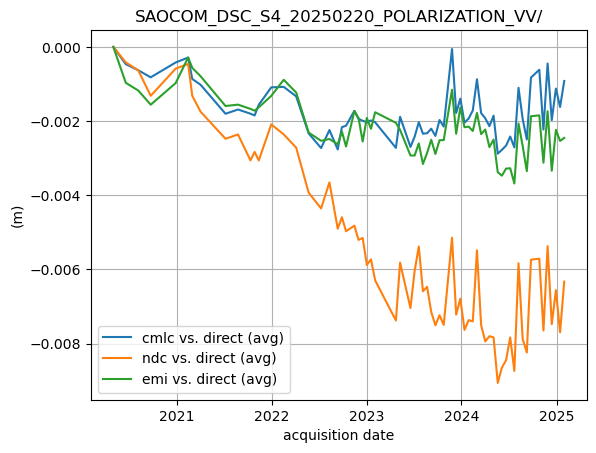

In [22]:
plt.close(1)
plt.figure(1)
plt.plot(dates, cmlc_bias*0.24/(4*np.pi), label="cmlc vs. direct (avg)")
plt.plot(dates, ndc_bias*0.24/(4*np.pi), label="ndc vs. direct (avg)")
plt.plot(dates,  (emi_bias - emi_bias[1])*0.24/(4*np.pi), label="emi vs. direct (avg)")
plt.xlabel("acquisition date")
plt.ylabel("(m)")
plt.legend()
plt.grid()
plt.title(channel_dir)


Text(0.5, 1.0, 'SAOCOM_DSC_S4_20250220_POLARIZATION_VV/')

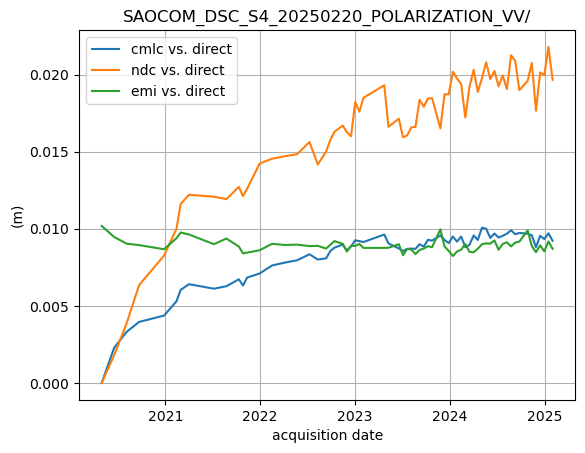

In [23]:
plt.close(1)
plt.figure(1)
plt.plot(dates, cmlc_std*0.24/(4*np.pi), label="cmlc vs. direct")
plt.plot(dates, ndc_std*0.24/(4*np.pi), label="ndc vs. direct")
plt.plot(dates,  (emi_std )*0.24/(4*np.pi), label="emi vs. direct")
plt.xlabel("acquisition date")
plt.ylabel("(m)")
plt.legend()
plt.grid()
plt.title(channel_dir)

Text(0.5, 1.0, 'SAOCOM_DSC_S4_20250220_POLARIZATION_VV/')

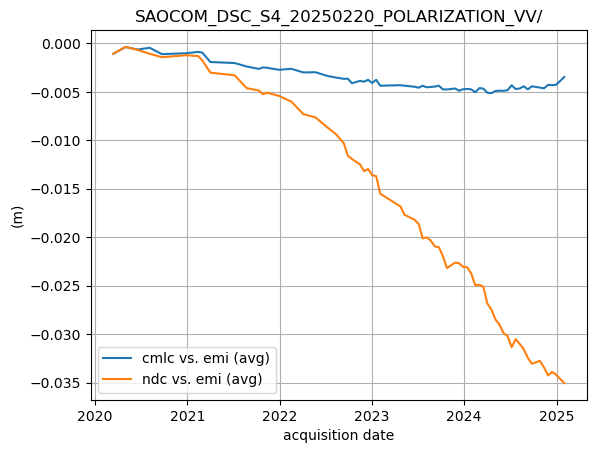

In [25]:
plt.close(1)
plt.figure(1)
plt.plot(dates,-np.cumsum(cmlc_emi_bias_s1)*0.24/(4*np.pi),label="cmlc vs. emi (avg)")
plt.plot(dates,-np.cumsum(ndc_emi_bias_s1)*0.24/(4*np.pi),label="ndc vs. emi (avg)")
plt.xlabel("acquisition date")
plt.ylabel("(m)")
plt.legend()
plt.grid()
plt.title(channel_dir)